# NN_L8_gan_density

**Lecture 8 of Neural Networks and Deep Learning (NN). Density (log scale) of standardised S&P 500 daily log returns 2005-2019, of 200,000 GAN samples (seed 1) and of the Gaussian.**

Neural Networks and Deep Learning (NN), Lecture 8 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L8/NN_L8_gan_density/NN_L8_gan_density.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Excess kurtosis and 1 % quantile of real returns; GAN samples from the trained generator.

excess kurtosis, real = 11.86   [gan.kurt_real]
1 % quantile of daily returns (%) = -3.48   [gan.var_real_pct]
training days = 3774   [gan.n_train]


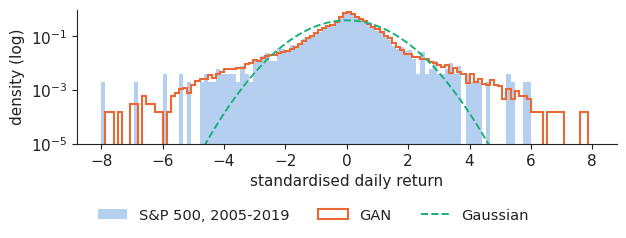

In [3]:
x = pd.read_csv(DATA + 'markets_daily.csv', parse_dates=['date'])
px = x[x.ticker == 'SP500'].set_index('date')['adjclose'].dropna()
end = (px.index.max() + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)
r = np.log(px.loc[:end]).diff().dropna()
rtr = r.loc[:'2019-12-31']
s_tr = float(rtr.std())
ztr = rtr.values / s_tr
from scipy import stats
g = pd.read_csv(REPO + 'lectures/L8/results/' + 'gan_samples.csv').gan_seed1.values / s_tr
show('gan.kurt_real', 'excess kurtosis, real', round(float(stats.kurtosis(ztr)), 2))
show('gan.var_real_pct', '1 % quantile of daily returns (%)', round(100 * float(np.quantile(ztr, 0.01)) * s_tr, 2))
show('gan.n_train', 'training days', len(rtr))
b = np.linspace(-8, 8, 121)
fig, ax = plt.subplots(figsize=(6.4, 2.5))
ax.hist(ztr, bins=b, density=True, histtype='stepfilled', alpha=0.35, color=PAL['data'], label='S&P 500, 2005-2019')
ax.hist(g, bins=b, density=True, histtype='step', lw=1.5, color=PAL['model'], label='GAN')
xx = np.linspace(-8, 8, 400)
ax.plot(xx, stats.norm.pdf(xx), '--', color=PAL['benchmark'], label='Gaussian')
ax.set_yscale('log'); ax.set_ylim(1e-5, 1)
ax.set_xlabel('standardised daily return'); ax.set_ylabel('density (log)')
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('gan_density.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()